# Lab: Exploratory Data Analysis (EDA) & Dashboard Generation

## Objectives
By the end of this lab, you will:
- Perform Univariate, Bivariate, and Multivariate analysis
- Compute statistical summaries
- Detect outliers and skewness
- Explore relationships using correlation
- Apply transformations
- Build a simple dashboard layout using matplotlib


# 🟢 Imports & Setup

In [26]:
# ==============================
# 1. Imports
# Exploratory Data Analysis (EDA)
# Dataset: Airbnb Listings
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8")


https://www.kaggle.com/datasets/alhamdulliah123/student-placement-and-skills-analytics-dataset-2025/data 

In [27]:

# ==============================
# 2. Load Dataset
# ==============================

# TODO: Replace with your dataset
df = pd.read_csv("data/titanic_data.csv")

df_backup = df.copy()  # Keep a backup of the original data
df.head(5)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 🟢 3. Initial Exploration
نظرة عامة على الداتا

حجمها؟

عدد الأعمدة = عدد المعلومات features

 ايه نوع كل واحد عشان اعرف اتعامل معاه

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [29]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [30]:
# Check missing values
df.isnull().sum()
df.isnull().sum().sort_values(ascending=False)

Cabin          687
Age            177
Embarked         2
PassengerId      0
Name             0
Pclass           0
Survived         0
Sex              0
Parch            0
SibSp            0
Fare             0
Ticket           0
dtype: int64

In [31]:
''' Name three information you can get from the Initial Exploration above. '''

' Name three information you can get from the Initial Exploration above. '

## 🟢 4. Univariate Analysis 
نظرة بدقة في كل عمود

1. how is the age of the passengers
2. what are their classes?
3. how much did they pay for the trip?

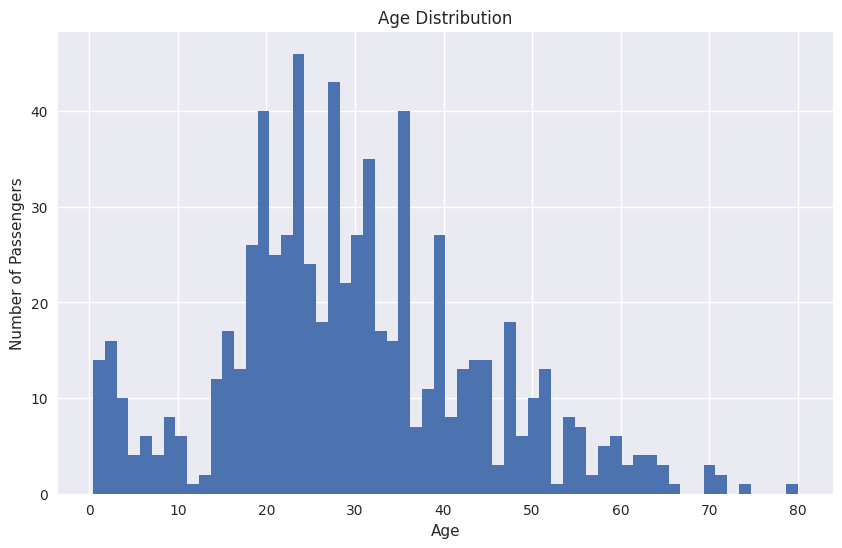

In [32]:
# ==============================
# 1. Histogram for Numerical Column
# ==============================
col = "Age"
plt.figure(figsize=(10, 6))
plt.hist(df[col], bins=60)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()

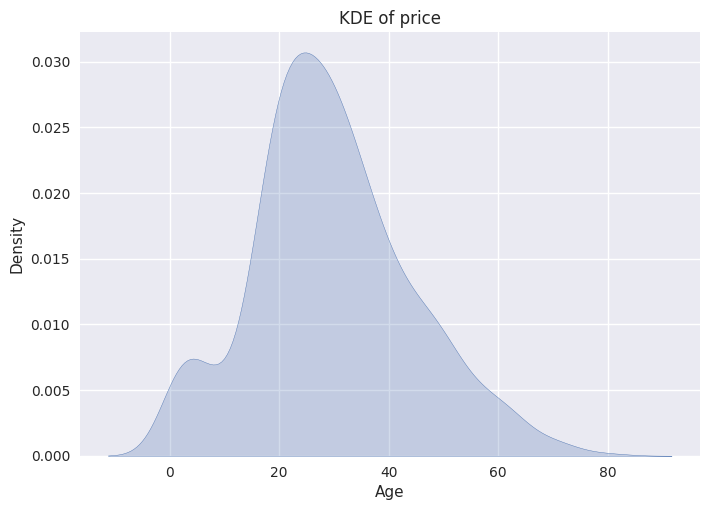

In [33]:
sns.kdeplot(df["Age"], fill=True)
plt.title("KDE of price")
plt.show()

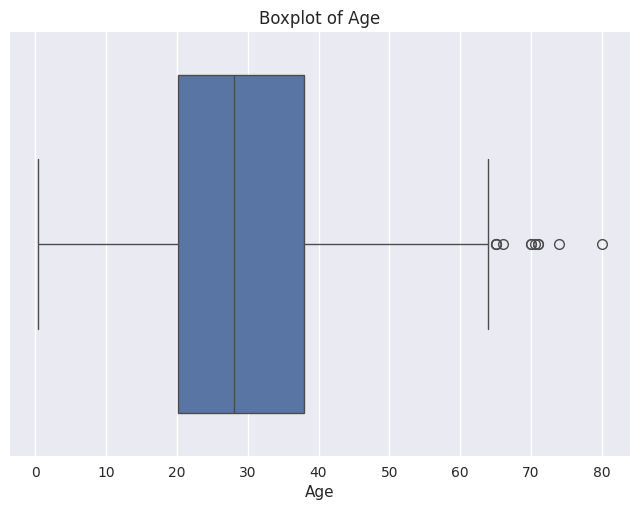

In [34]:
sns.boxplot(x=df[col])
plt.title(f"Boxplot of {col}")
plt.show()

In [35]:
df[col].skew(), df[col].kurt()

(np.float64(0.38910778230082704), np.float64(0.17827415364210353))

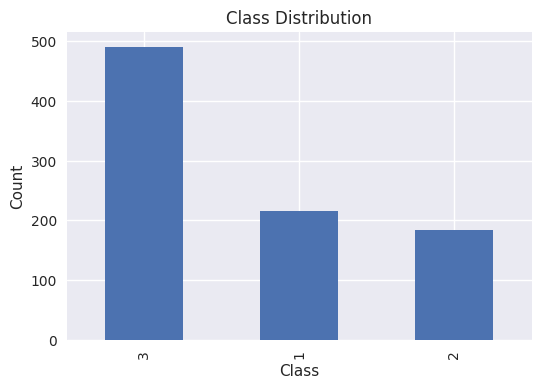

In [ ]:
plt.figure(figsize=(6,4))
df["Pclass"].value_counts().plot(kind="bar")
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

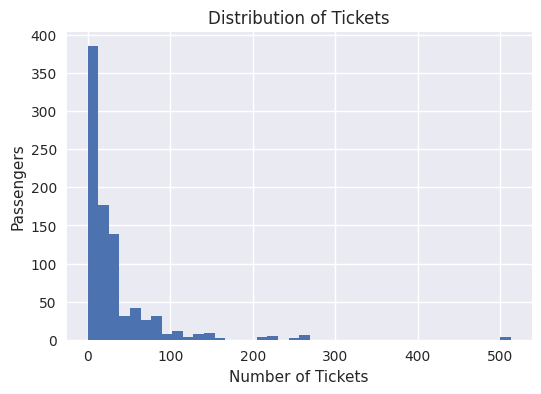

In [ ]:

plt.figure(figsize=(6,4))
plt.hist(df["Fare"], bins=40)
plt.title("Distribution of Tickets")
plt.xlabel("Number of Tickets")
plt.ylabel("Passengers")
plt.show()

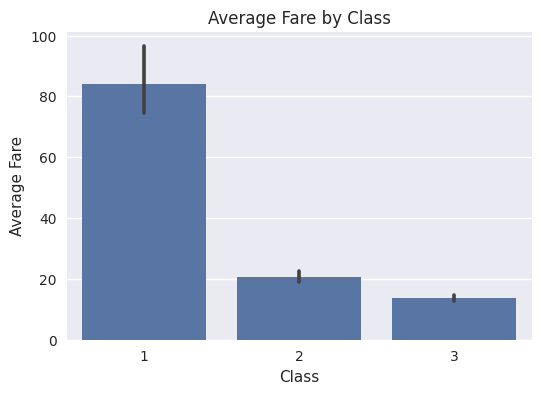

In [ ]:
# average fare by class

plt.figure(figsize=(6,4))
sns.barplot(x="Pclass", y="Fare", data=df)
plt.title("Average Fare by Class")
plt.xlabel("Class")
plt.ylabel("Average Fare")
plt.show()

## 🟢 6. Bivariate Analysis
طيب والعلاقات بين الداتا ايه نظامها؟

خلينا ناخد عمودين ونبص عليهم سوا- 

أو two features يعني
### Questions
1. did more females survive than males?
2. were all the children saved in the crisis?
3. did the people with authority focus on saving only the rich?
4. did people of same Embarkation suffer the same fate?

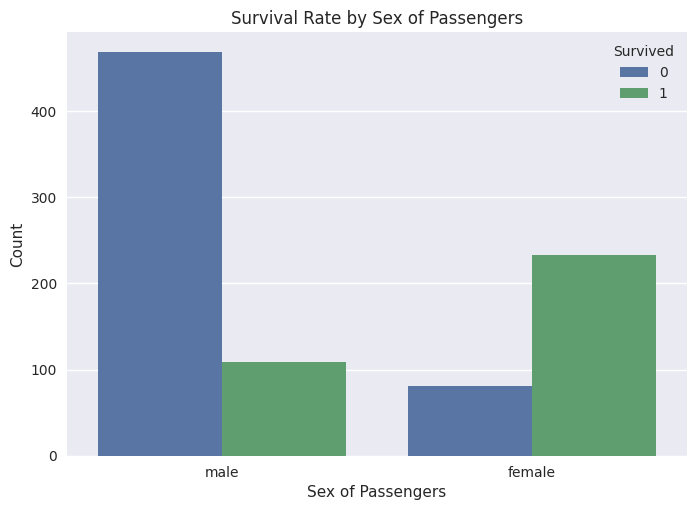

In [ ]:
# sex distribution of passengers with survival rate

sns.countplot(x="Sex", hue="Survived", data=df)
plt.title("Survival Rate by Sex of Passengers")
plt.xlabel("Sex of Passengers")
plt.ylabel("Count")
plt.show()

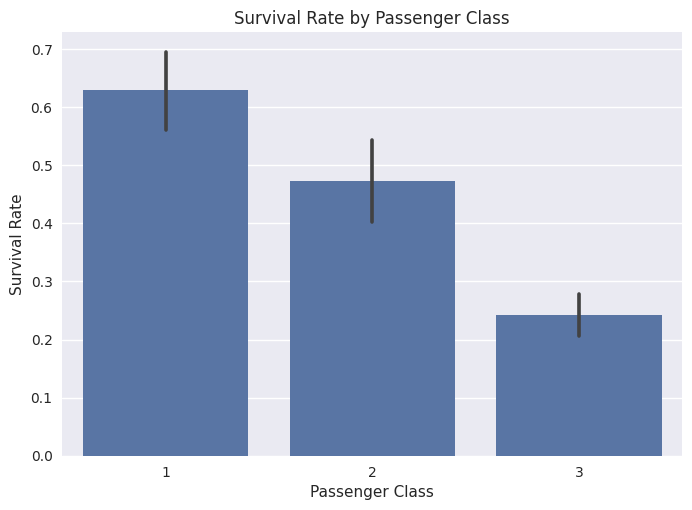

In [40]:
# survival by Pclass but considering the weight of each class (number of passengers in each class)
sns.barplot(x="Pclass", y="Survived", data=df) # default estimator is mean, so it will give us 
                                                # the survival rate for each class
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

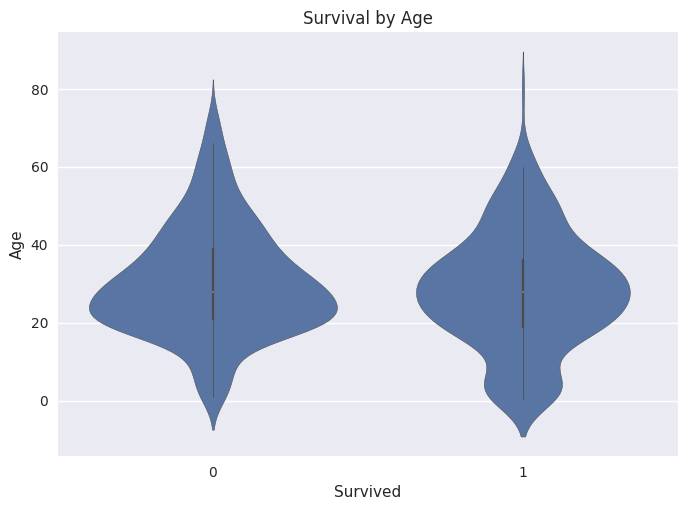

In [ ]:
# now survival by Age using violin plot to see the distribution of ages for survived and not survived passengers

sns.violinplot(x="Survived", y="Age", data=df)
plt.title("Survival by Age")
plt.xlabel("Survived")
plt.ylabel("Age")
plt.show()

In [42]:
# understand violin plot: the side part means the density of the data, 
# so the wider part means more passengers in that age group. 
# The line in the middle of the violin plot represents the median age for each group (survived and not survived).

# the violin plot above shows more survival rates in children and young adults 
#   (the bulk of the data is in the lower age groups).

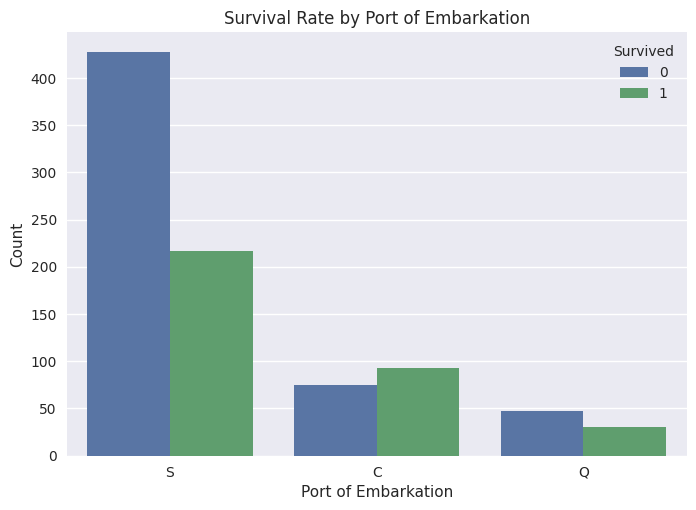

In [ ]:
# survival with Embarked

sns.countplot(x="Embarked", hue="Survived", data=df)
plt.title("Survival Rate by Port of Embarkation")
plt.xlabel("Port of Embarkation")
plt.ylabel("Count")
plt.show()

## 🟢 7. Multivariate Analysis
نبص على كله مرة واحدة

## 7.1 Correlation
الكوريليشن قيمة مهمة جدا بتقولي اد ايه الداتا مرتبطة ببعضها ولا مفيش بينها ارتباط

ارتباط يعني علاقة طردية أو عكسية

يعي ال فيتشرز بتتحرك سوا ولا لأ

### heatmap 

طريقة ظريفة لتلوين ماتريكس الكوريلشن- اللون الغامق هو رقم أكبر والفاتح هو رقم أقل

هنا العلاقات مش قوية أوي



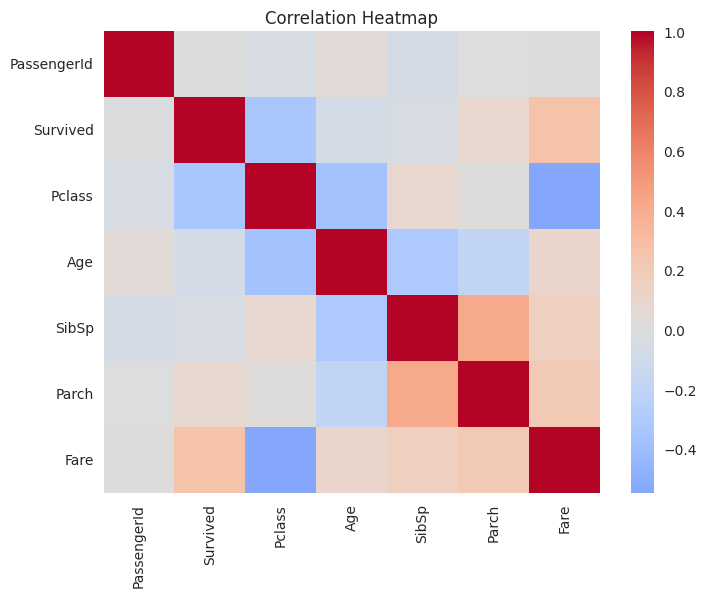

In [44]:
numeric_cols = df.select_dtypes(include=np.number)

plt.figure(figsize=(8,6))
sns.heatmap(numeric_cols.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

In [45]:
''' correlation is very weak here meaning:

what does correlation=1 mean here? '''

' correlation is very weak here meaning:\n\nwhat does correlation=1 mean here? '

### Q: lets talk about survival rate with Age and Sex

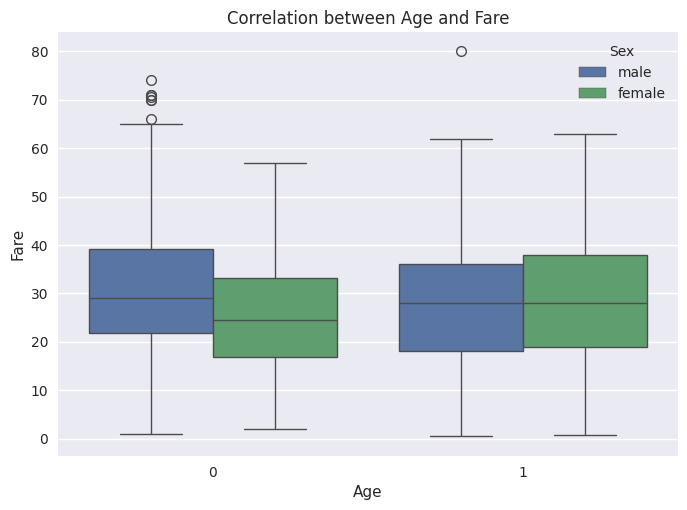

In [46]:
# correlation with age and survival 
# show numers on the box plot
sns.boxplot(data=df, x="Survived", y="Age", hue="Sex") 
plt.title("Correlation between Age and Fare")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.show()

## 7.2 Pairplot 
for example , not very insightful here

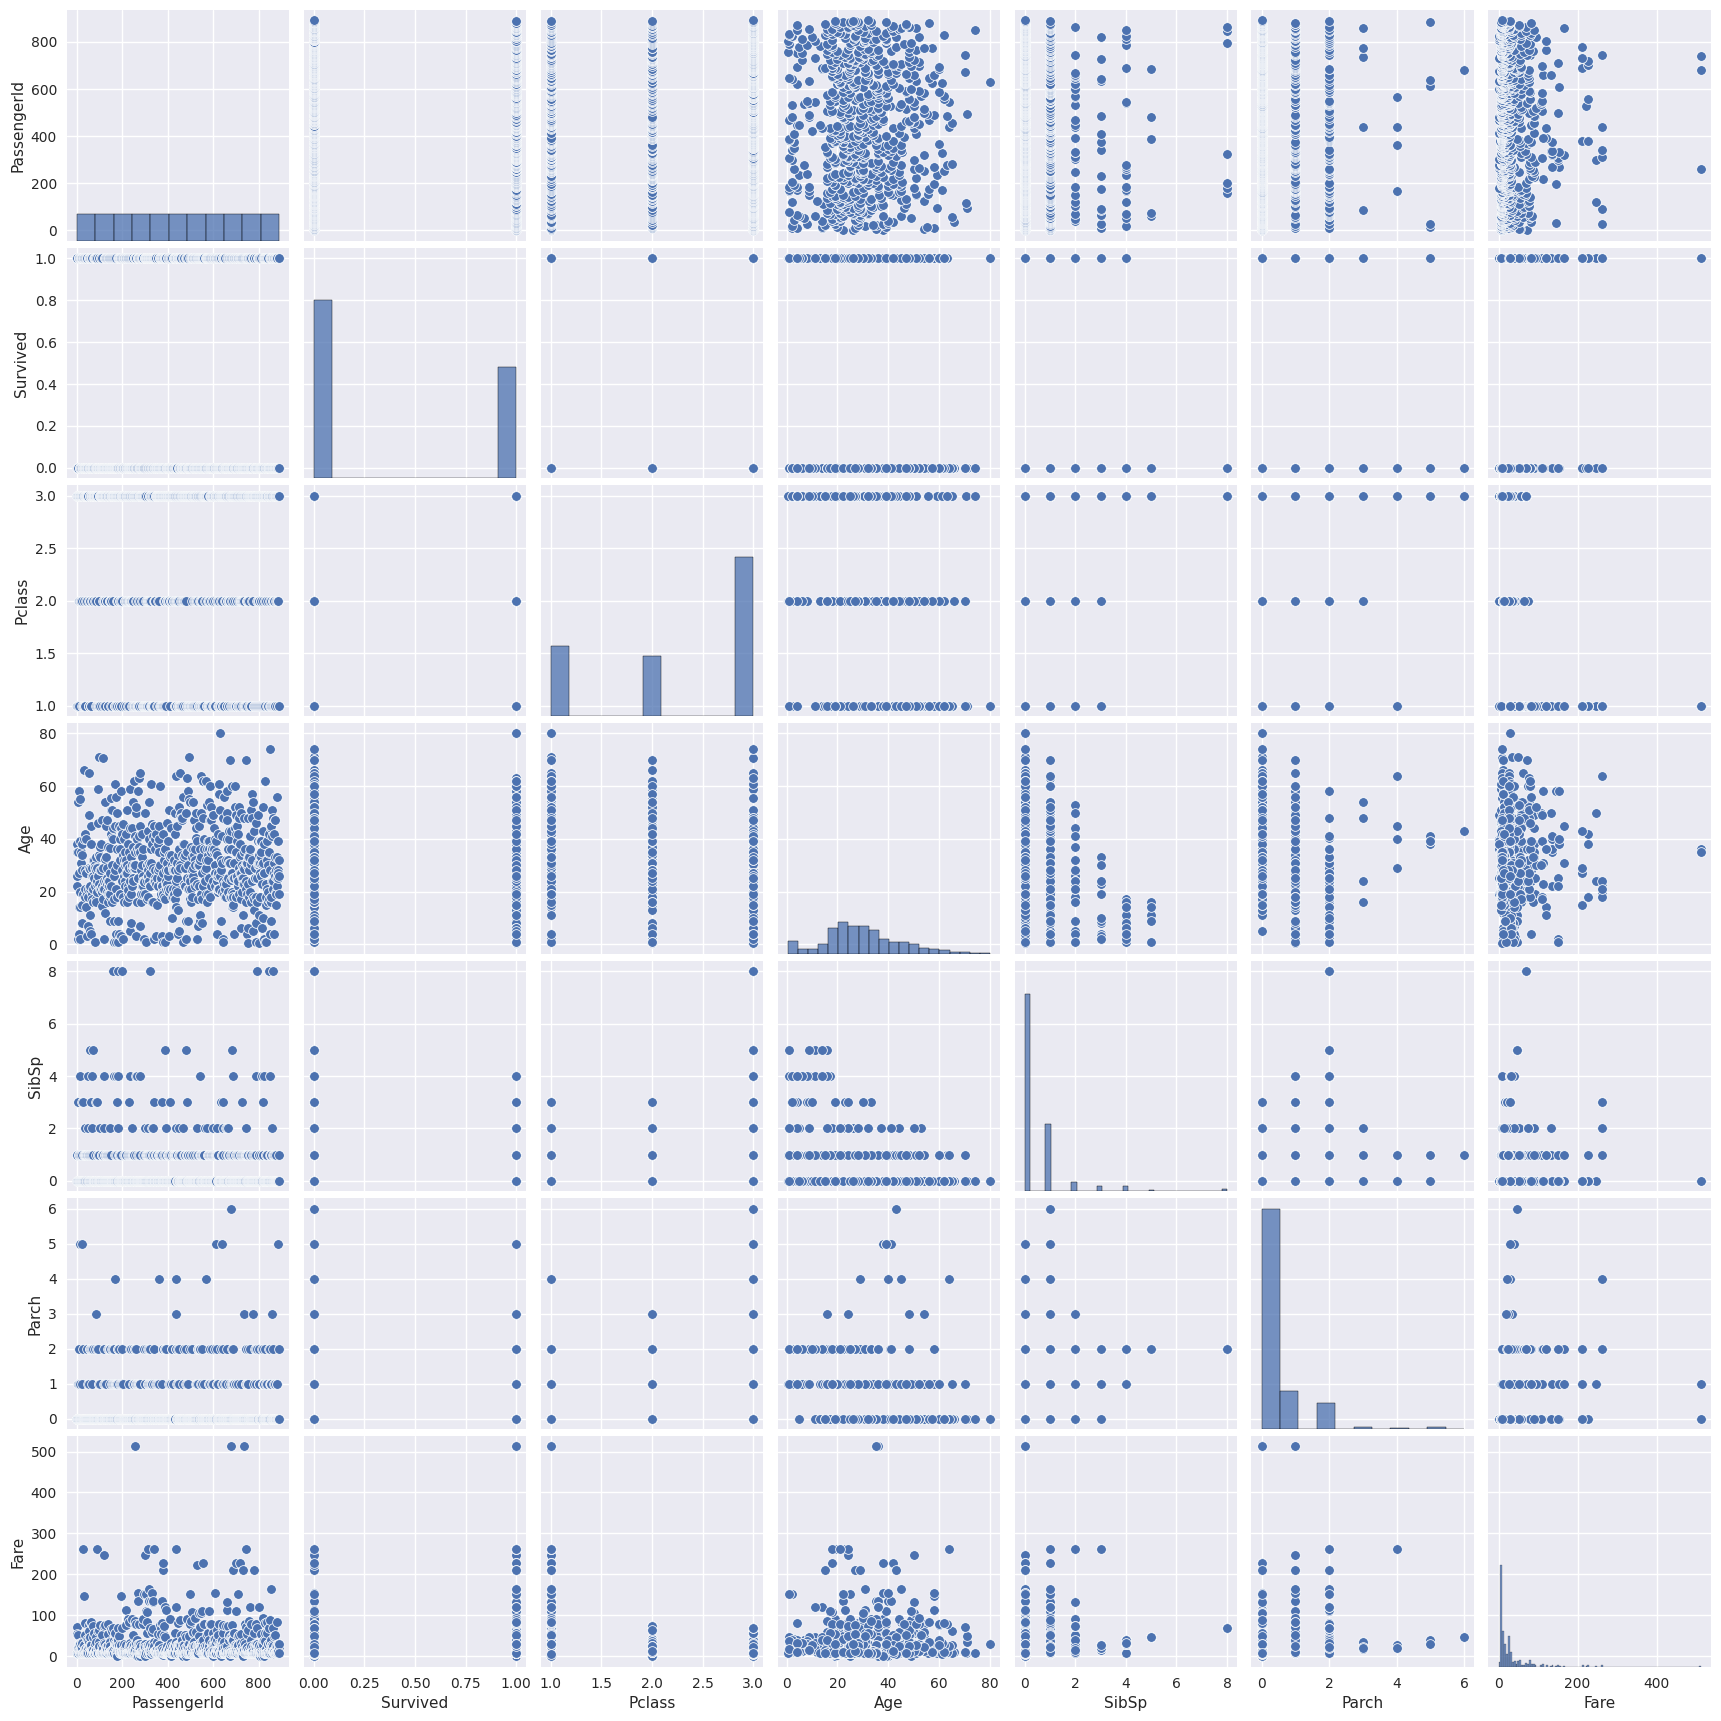

In [47]:
sns.pairplot(df) 
plt.show()

## 🟢 Final Dashboard

Text(0.5, 1.0, 'Survival Rate by Port of Embarkation')

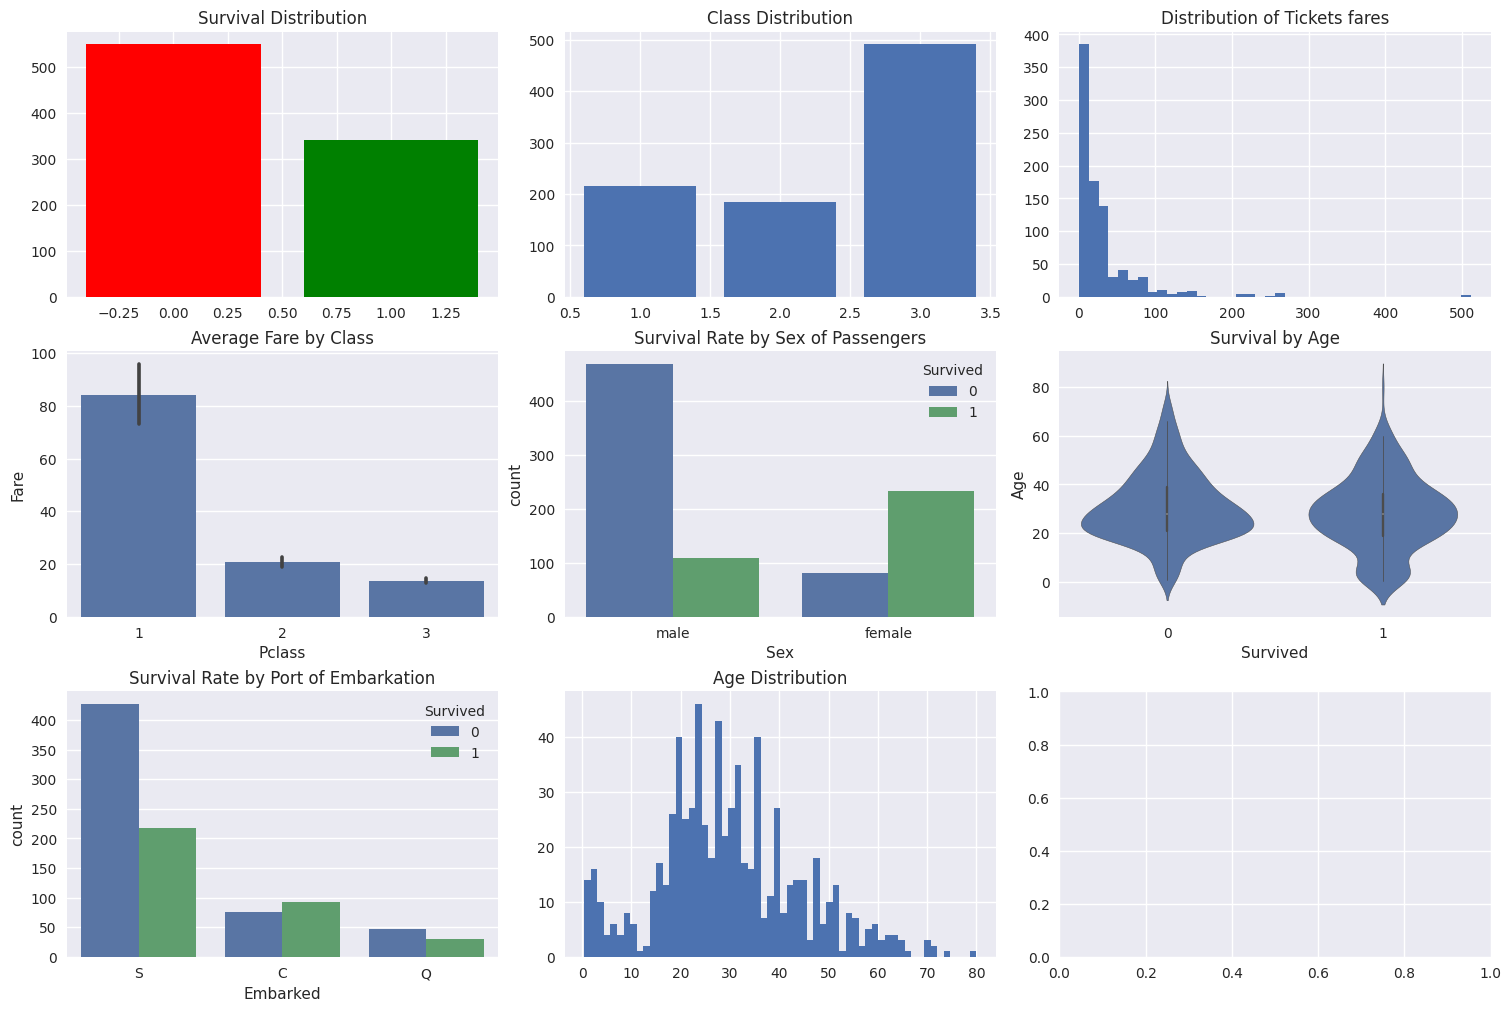

In [65]:
# we can put all previous plots in one figure to create a useful dash board
fig, axes = plt.subplots(3, 3, figsize=(15, 10) , constrained_layout=True)
# first plot is the number of survived passengers


axes[0, 0].bar(df["Survived"].value_counts().index, df["Survived"].value_counts().values, color=["red", "green"])
axes[0, 0].set_title("Survival Distribution")

axes[2, 1].hist(df["Age"], bins=60)
axes[2, 1].set_title("Age Distribution")

axes[0, 1].bar(df["Pclass"].value_counts().index, df["Pclass"].value_counts().values)
axes[0, 1].set_title("Class Distribution")
axes[0, 2].hist(df["Fare"], bins=40)
axes[0, 2].set_title("Distribution of Tickets fares")
sns.barplot(x="Pclass", y="Fare", data=df, ax=axes[1, 0])
axes[1, 0].set_title("Average Fare by Class")
sns.countplot(x= "Sex", hue="Survived", data=df, ax=axes[1, 1])
axes[1, 1].set_title("Survival Rate by Sex of Passengers")
sns.violinplot(x="Survived", y="Age", data=df, ax=axes[1, 2])
axes[1, 2].set_title("Survival by Age")
sns.countplot(x="Embarked", hue="Survived", data=df, ax=axes[2, 0])
axes[2, 0].set_title("Survival Rate by Port of Embarkation")


In [ ]:
.value_counts()

Survived
1    342
Name: count, dtype: int64